In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

df = pd.read_csv("data/dataset.csv")

df["Datetime"] = pd.to_datetime(df["Datetime"])
df = df.sort_values("Datetime")
df = df.set_index("Datetime")

print(df.head())
print(df.shape)

                     PJME_MW
Datetime                    
2002-01-01 01:00:00  30393.0
2002-01-01 02:00:00  29265.0
2002-01-01 03:00:00  28357.0
2002-01-01 04:00:00  27899.0
2002-01-01 05:00:00  28057.0
(145366, 1)


In [41]:

print("Missing values:", df.isnull().sum())
print("Duplicate timestamps:", df.index.duplicated().sum())

df = df.groupby(level=0).mean()
df = df.asfreq("h")

print("Missing hours:", df["PJME_MW"].isna().sum())

# Fill missing values using time interpolation
df["PJME_MW"] = df["PJME_MW"].interpolate(method="time")

print("Final shape:", df.shape)

Missing values: PJME_MW    0
dtype: int64
Duplicate timestamps: 4
Missing hours: 30
Final shape: (145392, 1)


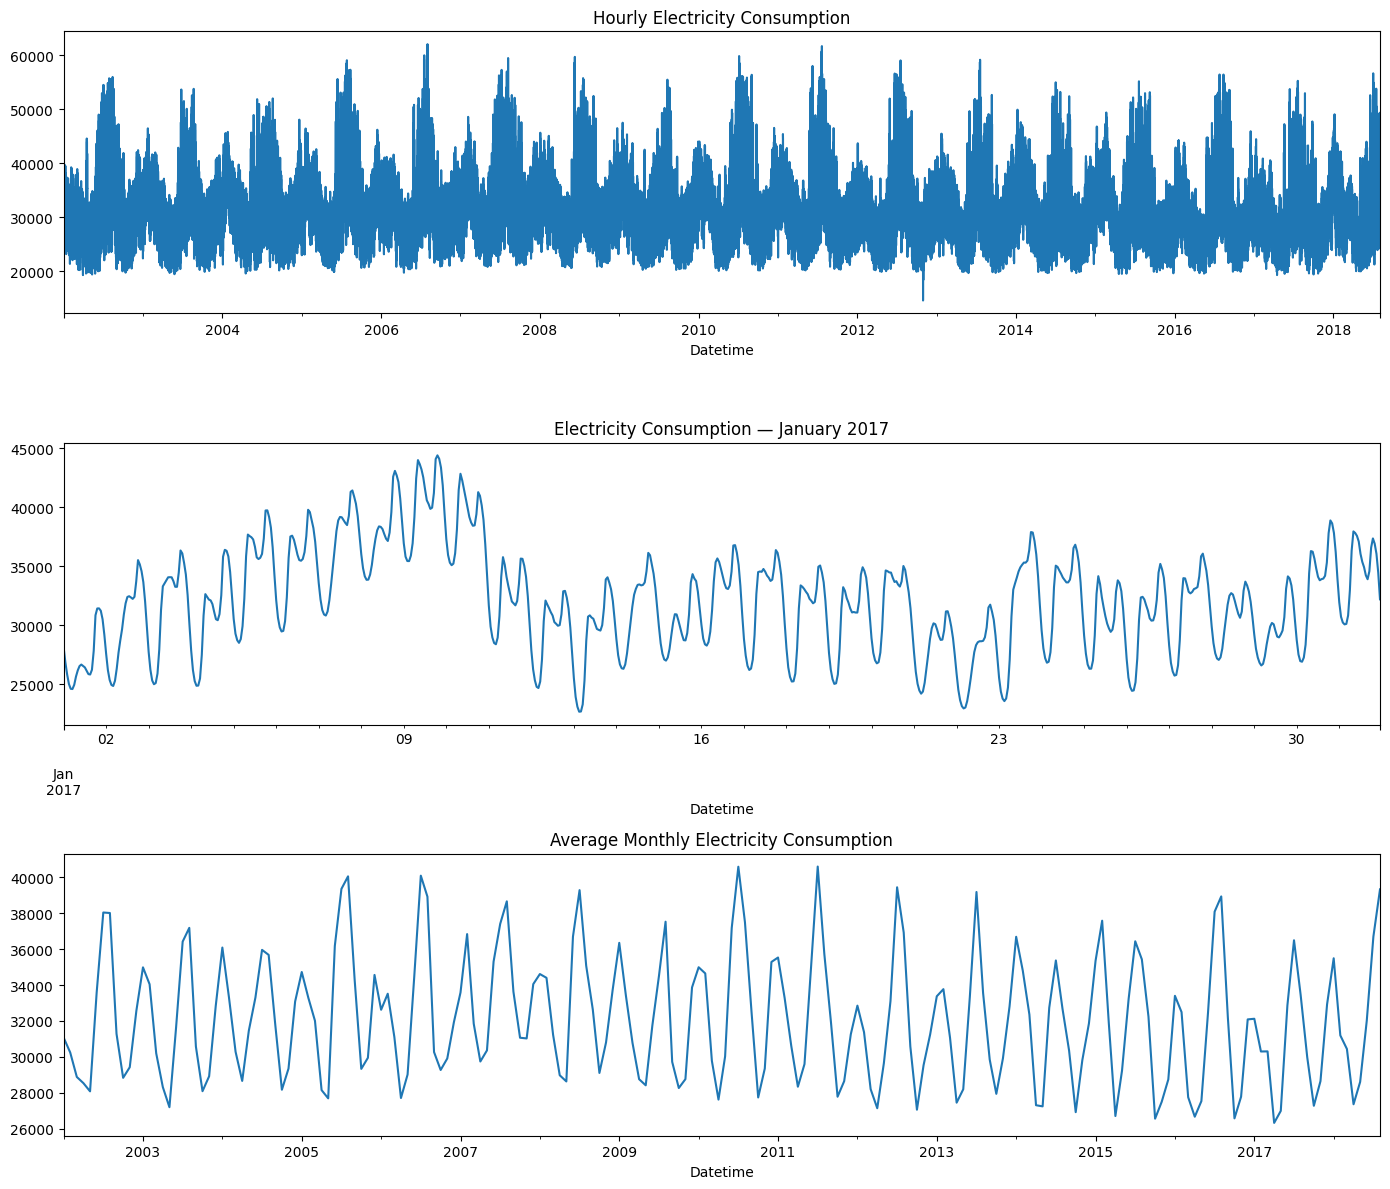

In [42]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12))

df["PJME_MW"].plot(ax=axes[0])
axes[0].set_title("Hourly Electricity Consumption")

df.loc["2017-01", "PJME_MW"].plot(ax=axes[1])
axes[1].set_title("Electricity Consumption — January 2017")

df["PJME_MW"].resample("MS").mean().plot(ax=axes[2])
axes[2].set_title("Average Monthly Electricity Consumption")

plt.tight_layout()
plt.show()

In [43]:

def create_features(data):
    data = data.copy()

    data["hour"] = data.index.hour
    data["dayofweek"] = data.index.dayofweek
    data["month"] = data.index.month
    data["year"] = data.index.year
    data["dayofyear"] = data.index.dayofyear

    data["lag_24"] = data["PJME_MW"].shift(24)
    data["lag_168"] = data["PJME_MW"].shift(168)

    return data

df_features = create_features(df)
df_features = df_features.dropna()

df_features.head()

,PJME_MW,hour,dayofweek,month,year,dayofyear,lag_24,lag_168
Datetime,,,,,,,,
2002-01-08 01:00:00,29445.0,1,1,1,2002,8,26862.0,30393.0
2002-01-08 02:00:00,28670.0,2,1,1,2002,8,25976.0,29265.0
2002-01-08 03:00:00,28375.0,3,1,1,2002,8,25641.0,28357.0
2002-01-08 04:00:00,28542.0,4,1,1,2002,8,25666.0,27899.0
2002-01-08 05:00:00,29261.0,5,1,1,2002,8,26328.0,28057.0


In [44]:

train = df_features.loc[df_features.index < "2017-01-01"].copy()
test = df_features.loc[df_features.index >= "2017-01-01"].copy()

y_train = train["PJME_MW"]
y_test = test["PJME_MW"]

print("Train:", train.shape)
print("Test:", test.shape)

Train: (131327, 8)
Test: (13897, 8)


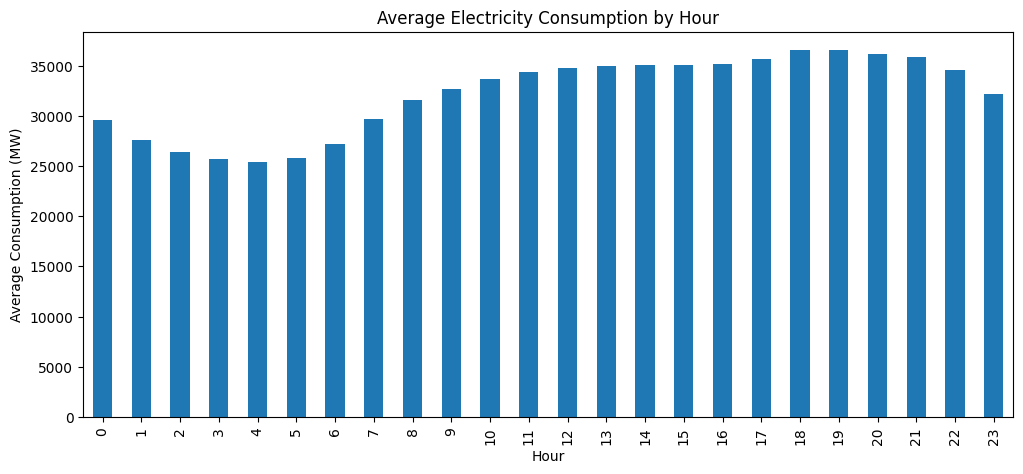

In [45]:

hourly_avg = train.groupby("hour")["PJME_MW"].mean()

hourly_avg.plot(kind="bar", figsize=(12, 5))

plt.title("Average Electricity Consumption by Hour")
plt.xlabel("Hour")
plt.ylabel("Average Consumption (MW)")
plt.show()

In [46]:

calendar_features = [
    "hour", "dayofweek", "month", "year", "dayofyear"
]

X_train_calendar = train[calendar_features]
X_test_calendar = test[calendar_features]

model_calendar = XGBRegressor(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    random_state=42,
    n_jobs=-1
)

model_calendar.fit(X_train_calendar, y_train)

pred_calendar = model_calendar.predict(X_test_calendar)

mae_calendar = mean_absolute_error(y_test, pred_calendar)
rmse_calendar = np.sqrt(mean_squared_error(y_test, pred_calendar))

print(f"Calendar MAE: {mae_calendar:.2f} MW")
print(f"Calendar RMSE: {rmse_calendar:.2f} MW")

Calendar MAE: 3084.57 MW
Calendar RMSE: 4163.03 MW


In [47]:

lag_features = [
    "hour", "dayofweek", "month", "year",
    "dayofyear", "lag_24", "lag_168"
]

X_train_lag = train[lag_features]
X_test_lag = test[lag_features]

model_lag = XGBRegressor(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    random_state=42,
    n_jobs=-1
)

model_lag.fit(X_train_lag, y_train)

pred_lag = model_lag.predict(X_test_lag)

mae_lag = mean_absolute_error(y_test, pred_lag)
rmse_lag = np.sqrt(mean_squared_error(y_test, pred_lag))

print(f"Lag MAE: {mae_lag:.2f} MW")
print(f"Lag RMSE: {rmse_lag:.2f} MW")

Lag MAE: 1915.92 MW
Lag RMSE: 2588.65 MW


                   Model         MAE        RMSE
      XGBoost (Calendar) 3084.567874 4163.028211
XGBoost (Calendar + Lag) 1915.918129 2588.647375


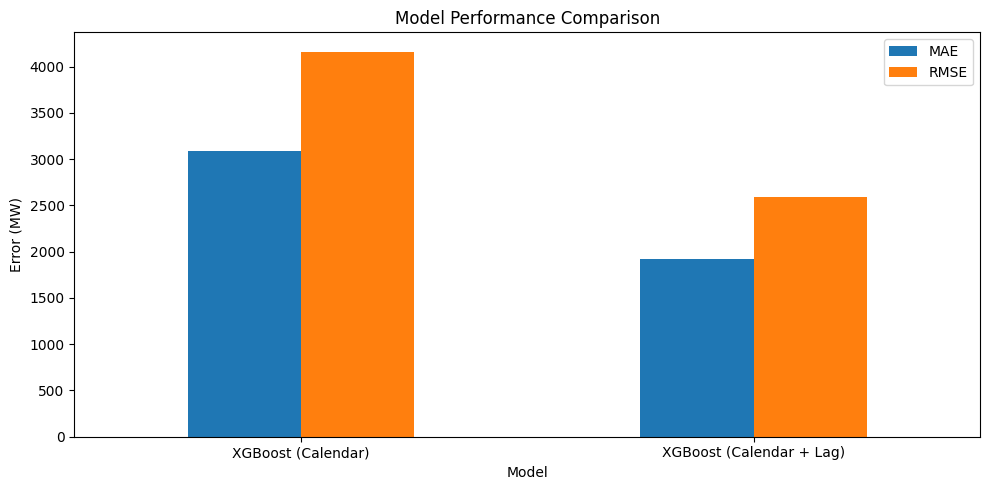

In [48]:

comparison = pd.DataFrame({
    "Model": [
        "XGBoost (Calendar)",
        "XGBoost (Calendar + Lag)"
    ],
    "MAE": [mae_calendar, mae_lag],
    "RMSE": [rmse_calendar, rmse_lag]
})

print(comparison.to_string(index=False))

comparison.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Error (MW)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

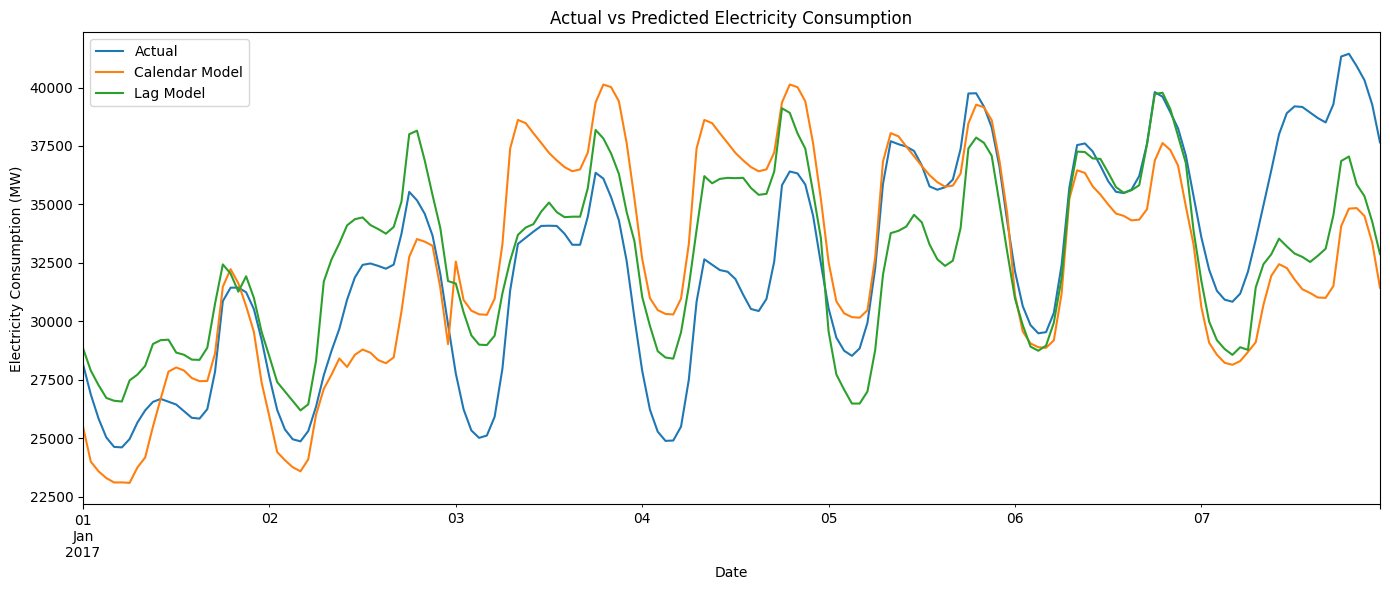

In [49]:

results = test[["PJME_MW"]].copy()

results["Calendar Prediction"] = pred_calendar
results["Lag Prediction"] = pred_lag

results.loc["2017-01-01":"2017-01-07"].plot(
    figsize=(14, 6)
)

plt.title("Actual vs Predicted Electricity Consumption")
plt.xlabel("Date")
plt.ylabel("Electricity Consumption (MW)")
plt.legend(["Actual", "Calendar Model", "Lag Model"])
plt.tight_layout()
plt.show()

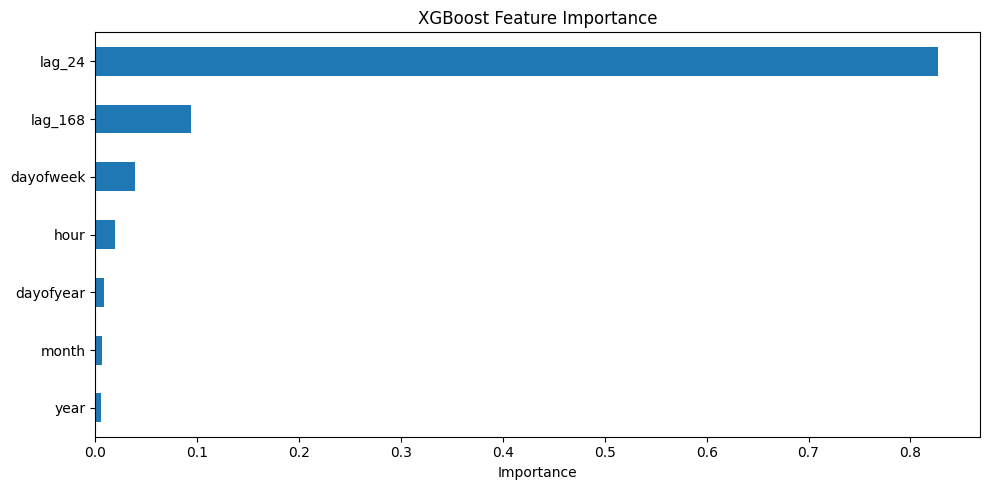

In [50]:

importance = pd.Series(
    model_lag.feature_importances_,
    index=lag_features
).sort_values()

importance.plot(kind="barh", figsize=(10, 5))

plt.title("XGBoost Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [51]:
best_model = comparison.loc[comparison["MAE"].idxmin()]

print("TIME SERIES FORECASTING RESULTS")
print("-" * 40)

print(f"Training samples: {len(train)}")
print(f"Testing samples: {len(test)}")

print(f"\nBest Model: {best_model['Model']}")
print(f"MAE: {best_model['MAE']:.2f} MW")
print(f"RMSE: {best_model['RMSE']:.2f} MW")

improvement = (
    (mae_calendar - mae_lag) / mae_calendar
) * 100

print(f"\nLag Feature MAE Improvement: {improvement:.2f}%")

TIME SERIES FORECASTING RESULTS
----------------------------------------
Training samples: 131327
Testing samples: 13897

Best Model: XGBoost (Calendar + Lag)
MAE: 1915.92 MW
RMSE: 2588.65 MW

Lag Feature MAE Improvement: 37.89%


In [52]:
results = test[["PJME_MW"]].copy()
results["predicted"] = predictions

results.loc["2017-01-01":"2017-01-07"].plot(figsize=(14, 5))

plt.title("Actual vs Predicted — XGBoost with Lag Features")
plt.xlabel("Date")
plt.ylabel("Electricity Consumption (MW)")
plt.legend(["Actual", "Predicted"])
plt.show()

ValueError: Length of values (13896) does not match length of index (13897)